In [1]:
# Importer les packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [2]:
# Import les données
df = pd.read_csv('/content/Car_Data.csv')
df.head()

,Marque,Année,Boite_Vitesse,Adresse,Prix,Venant_Occasion
0,Mitsubishi,2017,Automatique,"Liberte 6,Dakar",9750000,Venant
1,Ford,2009,Manuelle,"Yoff,Dakar",2500000,D'occasion
2,BMW,2015,Automatique,"Cité Damel,Dakar",15500000,D'occasion
3,Ford,2013,Automatique,"Almadies,Dakar",3800000,D'occasion
4,GMC,2014,Automatique,"Hlm,Dakar",7500000,Venant


In [3]:
# Afficher les infos des données
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5507 entries, 0 to 5506
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Marque           5507 non-null   object
 1   Année            5507 non-null   int64 
 2   Boite_Vitesse    5507 non-null   object
 3   Adresse          5507 non-null   object
 4   Prix             5507 non-null   int64 
 5   Venant_Occasion  5507 non-null   object
dtypes: int64(2), object(4)
memory usage: 258.3+ KB


**Exploration et préparation des données**

In [4]:
# selection les variables catégorielles
categoriel_data = df.select_dtypes(include = ['object'])
categoriel_data

,Marque,Boite_Vitesse,Adresse,Venant_Occasion
0,Mitsubishi,Automatique,"Liberte 6,Dakar",Venant
1,Ford,Manuelle,"Yoff,Dakar",D'occasion
2,BMW,Automatique,"Cité Damel,Dakar",D'occasion
3,Ford,Automatique,"Almadies,Dakar",D'occasion
4,GMC,Automatique,"Hlm,Dakar",Venant
...,...,...,...,...
5502,Kia,Automatique,"Liberte 6 extension,Dakar",Venant
5503,Mitsubishi,Manuelle,"Castor,Dakar",D'occasion
5504,Ford,Automatique,"Cité Damel,Dakar",D'occasion
5505,Mitsubishi,Automatique,"VDN,Dakar",Venant


In [5]:
# selection des variables quantitatives
number_data = df.select_dtypes(include = 'number')
number_data

,Année,Prix
0,2017,9750000
1,2009,2500000
2,2015,15500000
3,2013,3800000
4,2014,7500000
...,...,...
5502,2015,7800000
5503,2021,18500000
5504,2016,11700000
5505,2016,9000000


In [6]:
# décrire les variables catégorielles
categoriel_data.describe()

,Marque,Boite_Vitesse,Adresse,Venant_Occasion
count,5507,5507,5507,5507
unique,46,3,182,2
top,Ford,Automatique,"Almadies,Dakar",Venant
freq,1391,4675,765,2855


In [7]:
import plotly.express as px
def countplot_func(col):
    val  = df[col].value_counts()
    fig = px.bar(x = val.index, y = val.values, color =val.index.astype(str) , text_auto = True)
    fig.show()

In [8]:
for col in categoriel_data:
    countplot_func(col)

<Axes: xlabel='count', ylabel='Adresse'>

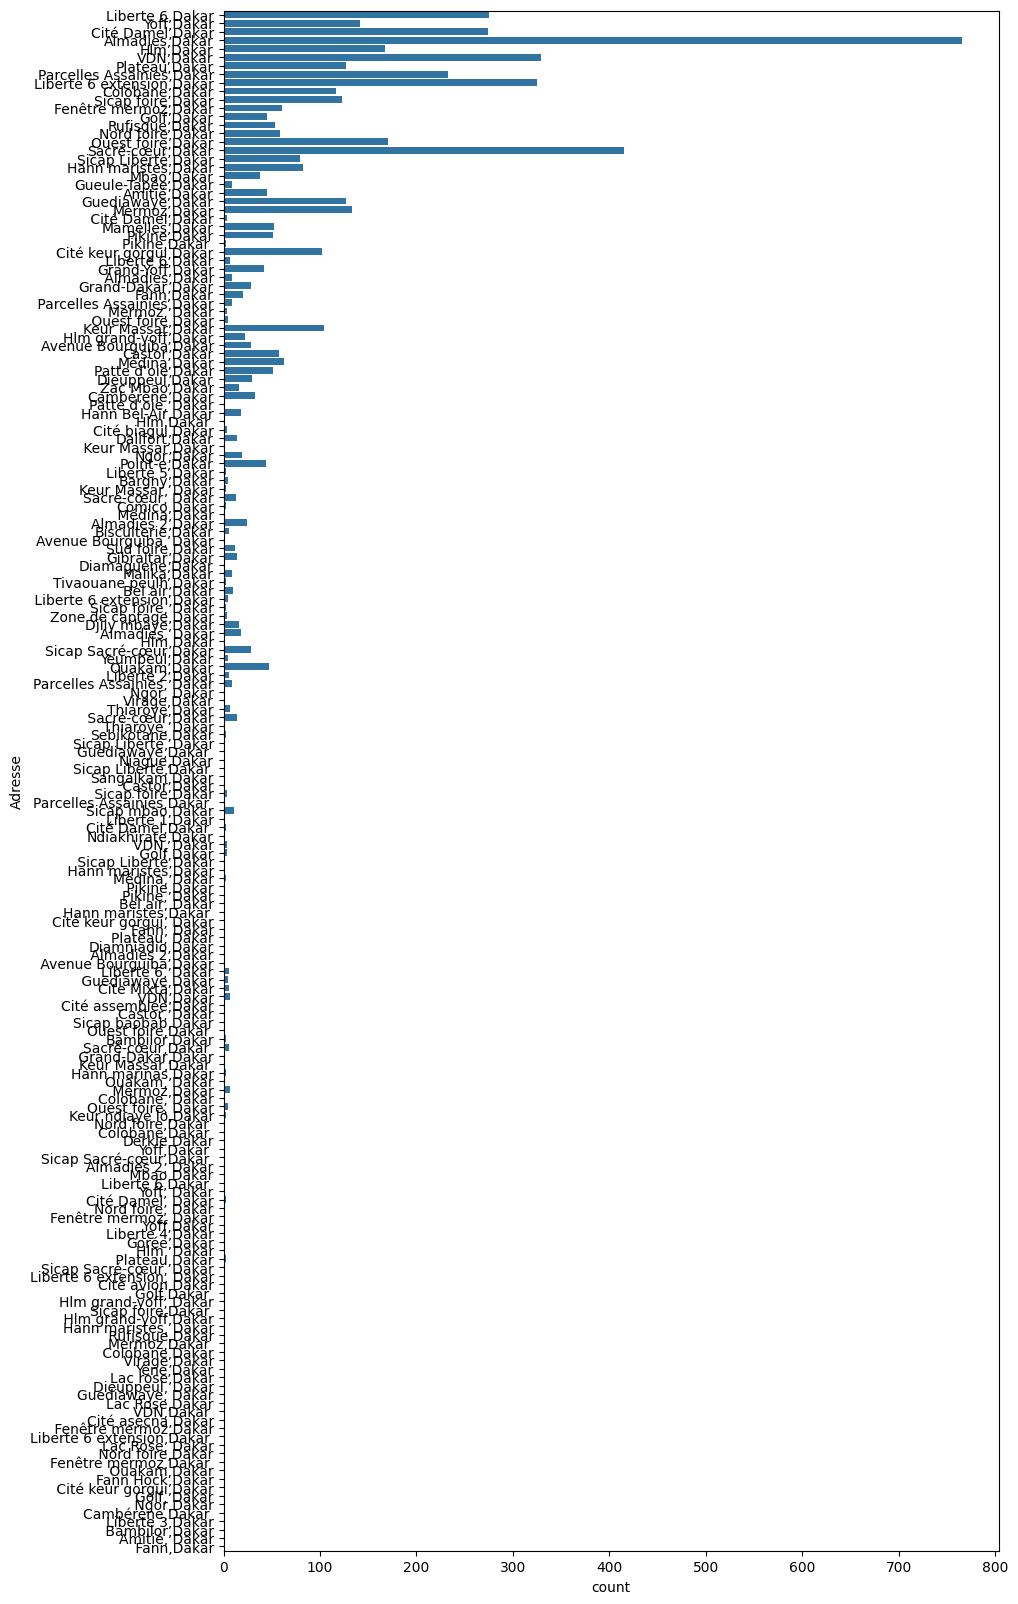

In [9]:
plt.figure(figsize=(10,20))
sns.countplot(data = categoriel_data, y = "Adresse")

In [10]:
# décrire les variables quantitatives
number_data.describe()

,Année,Prix
count,5507.000000,5.507000e+03
mean,2014.508444,1.110512e+07
std,3.089839,1.619639e+07
min,1990.000000,1.000000e+00
25%,2013.000000,4.600000e+06
50%,2015.000000,7.800000e+06
75%,2016.000000,1.250000e+07
max,2024.000000,7.794141e+08


In [11]:
# pairplot des variables quantitatives
for col in number_data:
    countplot_func(col)

In [12]:
# fonction de visualisation des boxplots
def boxplot_func(col):
  plt.figure(figsize=(25,3))
  sns.boxplot(x=df[col])
  plt.show()

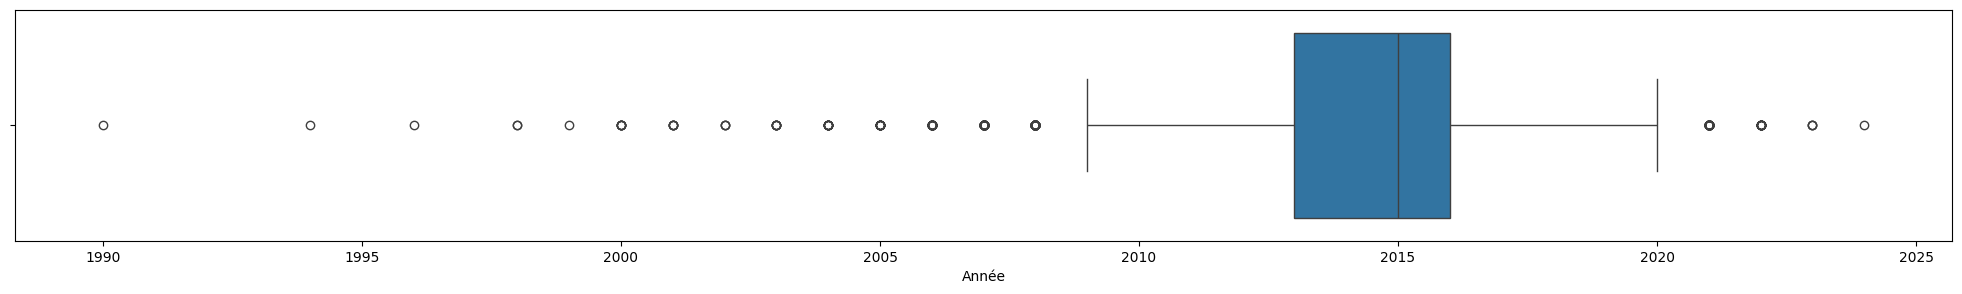

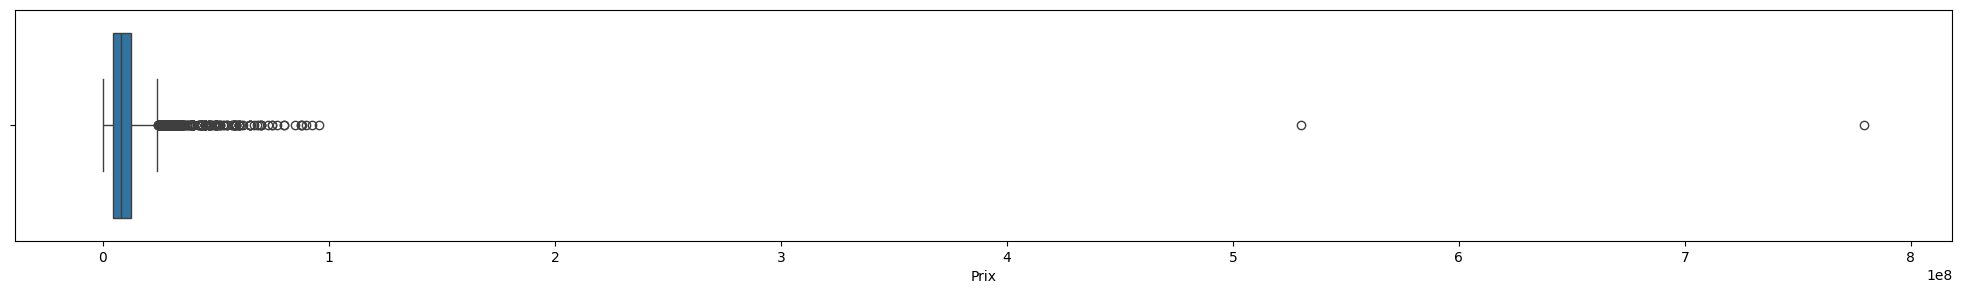

In [13]:
# boxplots des variables quantitatives
for col in number_data:
    boxplot_func(col)

In [14]:
# Supprimer ",Dakar" de la colonne Adresse
df['Adresse'] = df['Adresse'].str.replace(',Dakar', '', regex=False).str.strip()

# Mettre à jour categoriel_data pour prendre en compte la modification
categoriel_data = df.select_dtypes(include=['object'])

# Vérifier les premières valeurs modifiées
df['Adresse'].head()

,Adresse
0,Liberte 6
1,Yoff
2,Cité Damel
3,Almadies
4,Hlm


<Axes: xlabel='count', ylabel='Adresse'>

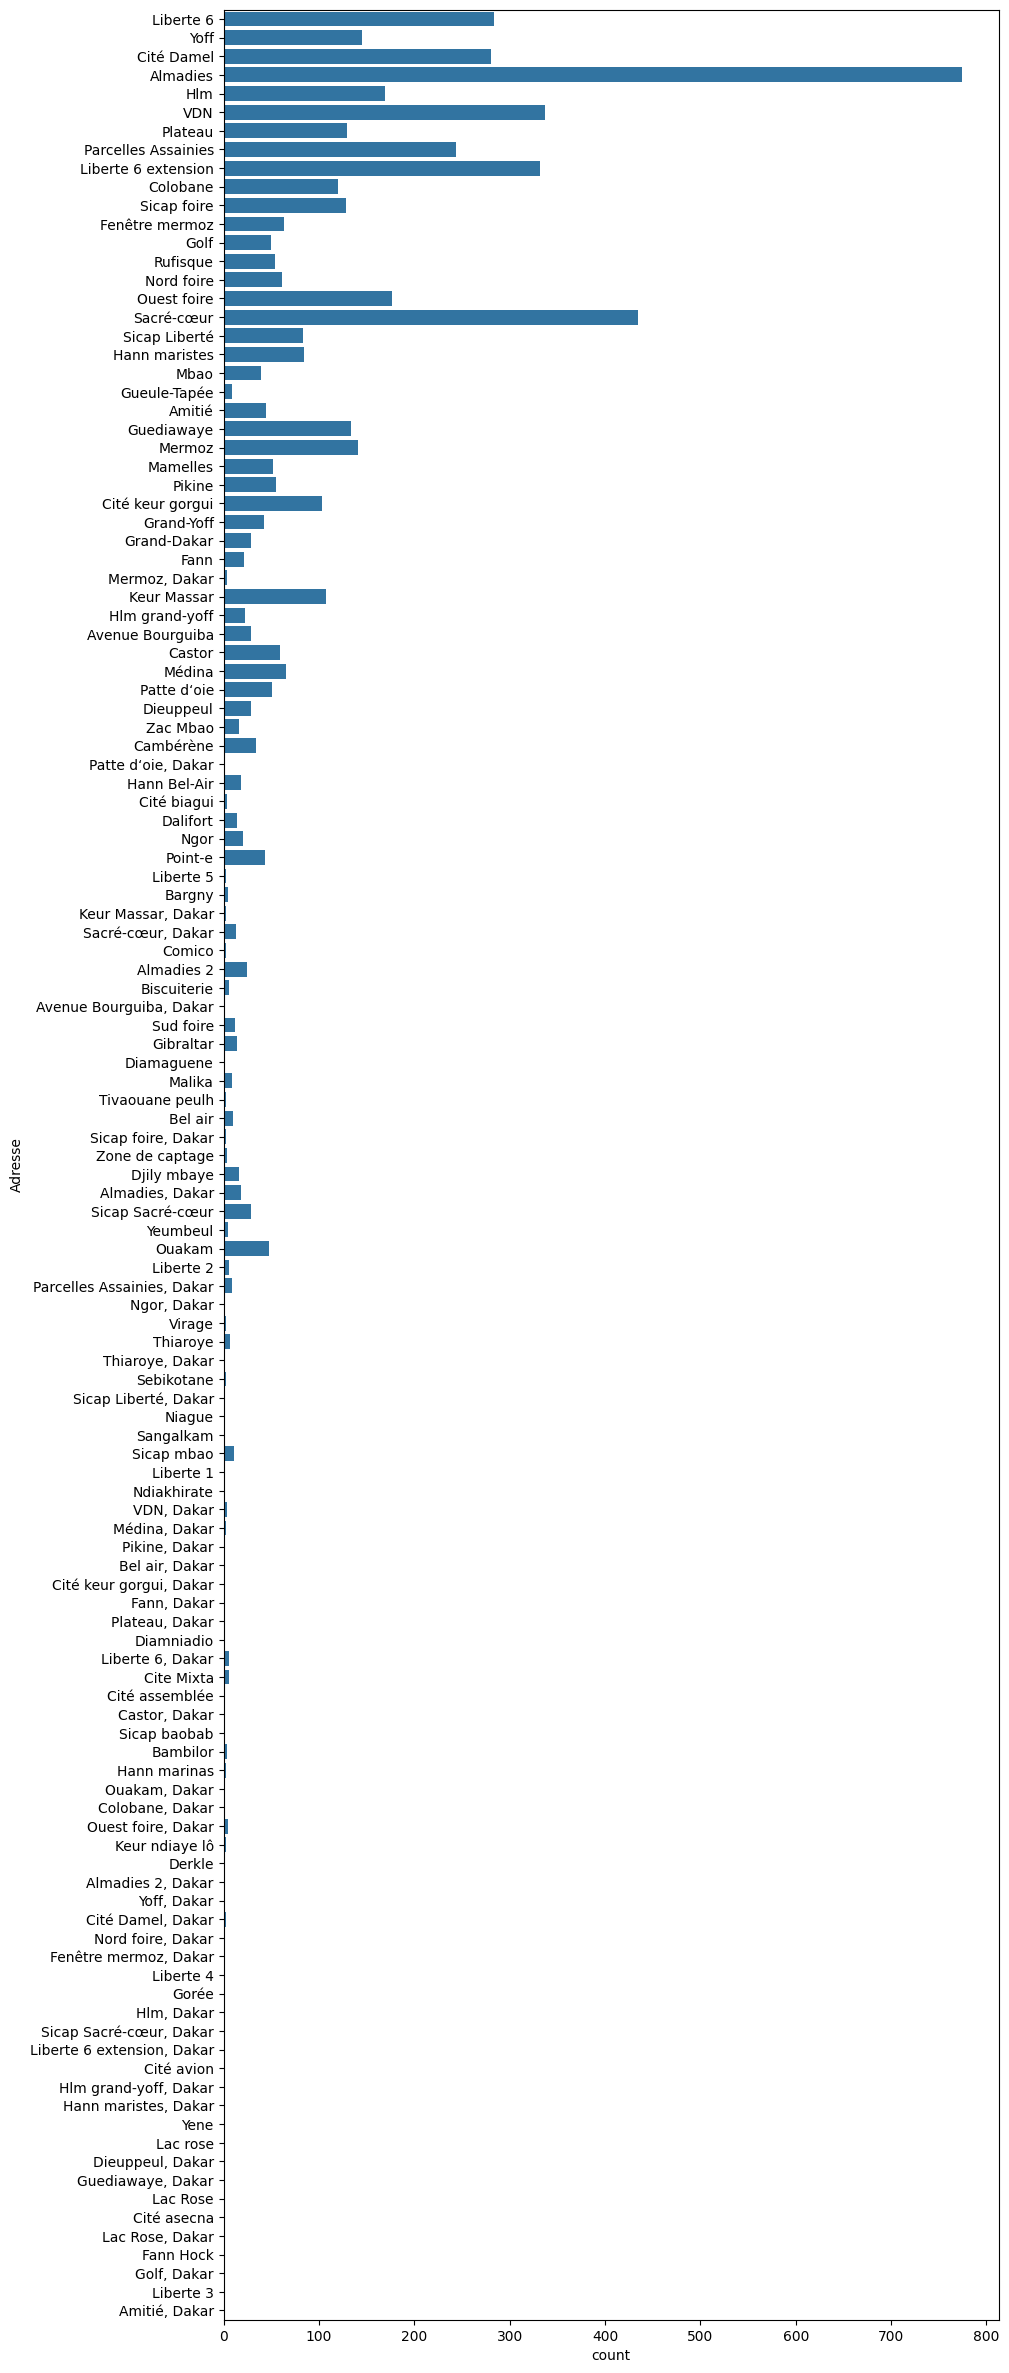

In [15]:
plt.figure(figsize=(10,30))
sns.countplot(data = categoriel_data, y = "Adresse")

In [16]:
# Encoder les variables catégorielles
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()
for col in categoriel_data.columns:
    df[col] = encoder.fit_transform(df[col])

    df.head()

In [17]:
# Fractionner les données en variables prédicteurs (x) et variable cibel(y)
x = df.drop('Venant_Occasion', axis=1).values
y = df['Venant_Occasion'].values

In [18]:
# normaliser les données
from sklearn .preprocessing import MinMaxScaler # Z = (X -Xmin)/(Xmax -Xmin)
scaler = MinMaxScaler()
x = scaler.fit_transform(x)
x[:5]

array([[0.66666667, 0.79411765, 0.        , 0.55284553, 0.01250939],
       [0.28888889, 0.55882353, 0.5       , 0.97560976, 0.00320754],
       [0.06666667, 0.73529412, 0.        , 0.13821138, 0.01988673],
       [0.28888889, 0.67647059, 0.        , 0.        , 0.00487546],
       [0.31111111, 0.70588235, 0.        , 0.43089431, 0.00962261]])

In [19]:
from sklearn.model_selection import train_test_split
x_train, x_val_test, y_train, y_val_test = train_test_split(x, y, train_size = 0.8, random_state = 42)
x_val, x_test, y_val, y_val_test = train_test_split(x_val_test, y_val_test, train_size = 0.5, random_state = 42)

In [20]:
from sklearn.model_selection import GridSearchCV
# Recherche des paramètres optimaux pour la logistic regression
from sklearn.linear_model import LogisticRegression
# dictionnaire params
params={"C":np.logspace(-3,3,10),"penalty": ['l1','l2']}
# instantier le modèle Logistic regression
lg=LogisticRegression()
# instantier le modèle gridsearch
grid=GridSearchCV(lg,params,cv=5)
# lancer la recherche
grid.fit(x_train,y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py:528: FitFailedWarning:


50 fits failed out of a total of 100.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
50 fits failed with the following error:
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/sklearn/base.py", line 1389, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py", line 1193, in fit
    solver = _check_solv

GridSearchCV(cv=5, estimator=LogisticRegression(),
             param_grid={'C': array([1.00000000e-03, 4.64158883e-03, 2.15443469e-02, 1.00000000e-01,
       4.64158883e-01, 2.15443469e+00, 1.00000000e+01, 4.64158883e+01,
       2.15443469e+02, 1.00000000e+03]),
                         'penalty': ['l1', 'l2']})

In [21]:
# Afficher les paramètres optimaux
grid.best_params_

{'C': np.float64(215.44346900318823), 'penalty': 'l2'}

In [22]:
# Entrainer la logistic regression en utilisant les paramètres optimaux
best_lg = grid.best_estimator_
best_lg.fit(x_train, y_train)

LogisticRegression(C=np.float64(215.44346900318823))

In [23]:
# fonction d'évaluation
from sklearn.metrics import f1_score, accuracy_score
def evaluation(model):
  y_pred = model.predict(x_val)
  acc = accuracy_score(y_val, y_pred)
  f1 = f1_score(y_val, y_pred, average='micro')
  return acc, f1

In [24]:
# Accuracy et F1 score du modèle sur les données de validation
acc_lg, f1_lg = evaluation(best_lg)
print(f"Régression Logistique -> Accuracy : {acc_lg:.4f} | F1-score : {f1_lg:.4f}")

Régression Logistique -> Accuracy : 0.7604 | F1-score : 0.7604


In [25]:
# Importer ConfusionMatrixDisplay
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
# y_pred:  prédictions du modèle sur les données validation
def CM_visualisation(model_objet):

    y_pred = model_objet.predict(x_val)
    # Confusion matrix
    classes = np.unique(y)
    cnf_matr = confusion_matrix(y_val, y_pred, labels=classes)

    # Utiliser ConfusionMatrixDisplay pour visualiser la matrice de confusion
    disp = ConfusionMatrixDisplay(confusion_matrix=cnf_matr,
                                 display_labels=encoder.classes_)
    disp.plot() # Afficher la matrice de confusion
    plt.title('Matrice de confusion - Régression Logistique') # Définir le titre
    plt.show() # Afficher la figure

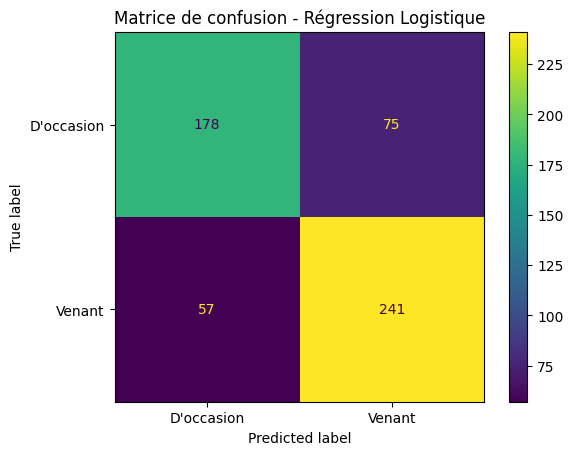

In [27]:
# Matrice de confusion
CM_visualisation(best_lg)

**Decision Tree**

In [28]:
# Recherche des paramètres optimaux pour le Decision Tree
from sklearn.tree import DecisionTreeClassifier
# dictionnaire des params
param__ = {'criterion':['gini','entropy'],'max_depth':np.arange(3,15)}
# instantier le modèle Decision Tree
dt = DecisionTreeClassifier(random_state=42)
# instantier le modèle gridsearch
grid__ = GridSearchCV(dt, param__, cv = 5)
# entrainer le modèle
grid__.fit(x_train, y_train)

GridSearchCV(cv=5, estimator=DecisionTreeClassifier(random_state=42),
             param_grid={'criterion': ['gini', 'entropy'],
                         'max_depth': array([ 3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14])})

In [29]:
# afficher les paramètres optimaux
grid__.best_params_

{'criterion': 'gini', 'max_depth': np.int64(6)}

In [30]:
# Entrainer le modèle en utilisant les paramètres optimaux
best_dt = grid__.best_estimator_
best_dt.fit(x_train, y_train)

DecisionTreeClassifier(max_depth=np.int64(6), random_state=42)

In [31]:
# Accuracy et F1 score du modèle sur les données de validation
acc_dt, f1_dt = evaluation(best_dt)
print(f"Decision Tree -> Accuracy : {acc_dt:.4f} | F1-score : {f1_dt:.4f}")

Decision Tree -> Accuracy : 0.8094 | F1-score : 0.8094


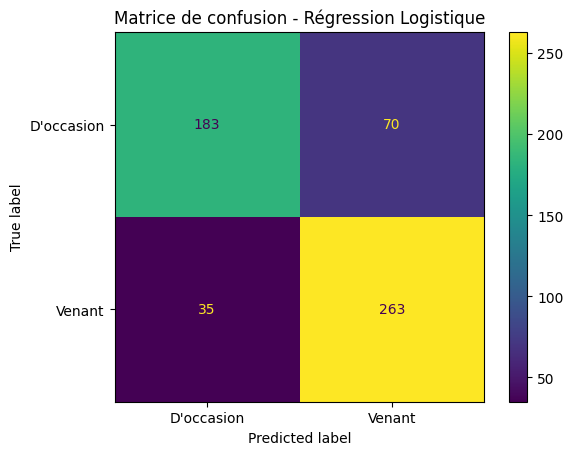

In [32]:
# Matrice de confusion
CM_visualisation(best_dt)

**Random Forest**

In [33]:
# Recherche des paramètres optimaux pour le Random Forest
from sklearn.ensemble import RandomForestClassifier
# dictionnaire des  params
params = param_grid = {
    'n_estimators': list(np.arange(10,100,10)),
    'max_depth' : list(np.arange(3,15)),
    'criterion' :['gini', 'entropy']
}
# instantier le modèle Random Forest
rf = RandomForestClassifier(random_state=42)
# instantier le modèle gridsearch
grid = GridSearchCV(estimator=rf, param_grid=params, cv= 5)
# entrainer le modèle
grid.fit(x_train, y_train)

GridSearchCV(cv=5, estimator=RandomForestClassifier(random_state=42),
             param_grid={'criterion': ['gini', 'entropy'],
                         'max_depth': [np.int64(3), np.int64(4), np.int64(5),
                                       np.int64(6), np.int64(7), np.int64(8),
                                       np.int64(9), np.int64(10), np.int64(11),
                                       np.int64(12), np.int64(13),
                                       np.int64(14)],
                         'n_estimators': [np.int64(10), np.int64(20),
                                          np.int64(30), np.int64(40),
                                          np.int64(50), np.int64(60),
                                          np.int64(70), np.int64(80),
                                          np.int64(90)]})

In [34]:
# Afficher les paramètres optimaux
grid.best_params_

{'criterion': 'gini', 'max_depth': np.int64(6), 'n_estimators': np.int64(50)}

In [35]:
# Entrainer Random Forest en utilisant les paramètres optimaux
best_rf = grid.best_estimator_
best_rf.fit(x_train, y_train)

RandomForestClassifier(max_depth=np.int64(6), n_estimators=np.int64(50),
                       random_state=42)

In [36]:
# Accuracy et F1 score du modèle sur les données de validation
acc_rf, f1_rf = evaluation(best_rf)
print(f"Random Forest -> Accuracy : {acc_rf:.4f} | F1-score : {f1_rf:.4f}")

Random Forest -> Accuracy : 0.8149 | F1-score : 0.8149


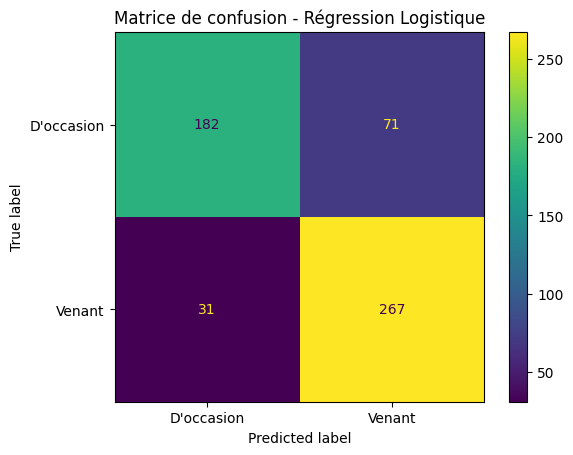

In [37]:
# Matrice de confusion
CM_visualisation(best_rf)

**tester le modele le plus performant**

=== Performances finales sur le Test Set ===
Accuracy sur le Test : 0.7913
F1-score sur le Test : 0.7913


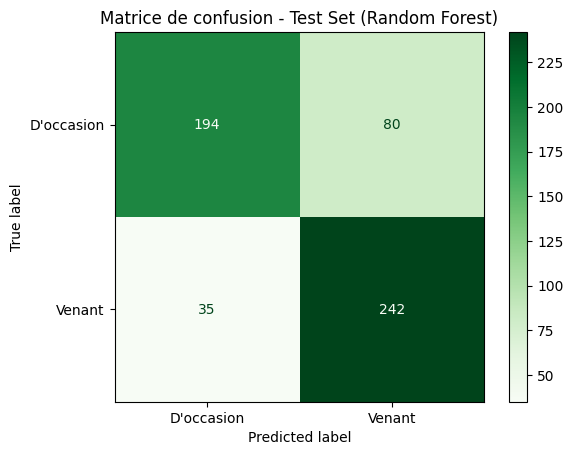

In [38]:
# 1. Évaluation du meilleur modèle (Random Forest) sur le jeu de test final
y_pred_test = best_rf.predict(x_test)
acc_test = accuracy_score(y_val_test, y_pred_test)
f1_test = f1_score(y_val_test, y_pred_test, average='micro')

print(f"=== Performances finales sur le Test Set ===")
print(f"Accuracy sur le Test : {acc_test:.4f}")
print(f"F1-score sur le Test : {f1_test:.4f}")

# 2. Visualisation de la Matrice de Confusion sur le Test Set
def CM_visualisation_test(model_objet):
    y_pred = model_objet.predict(x_test)
    classes = np.unique(y)
    cnf_matr = confusion_matrix(y_val_test, y_pred, labels=classes)

    disp = ConfusionMatrixDisplay(confusion_matrix=cnf_matr, display_labels=encoder.classes_)
    disp.plot(cmap=plt.cm.Greens) # En vert pour marquer la fin du pipeline !
    plt.title('Matrice de confusion - Test Set (Random Forest)')
    plt.show()

CM_visualisation_test(best_rf)

In [39]:
import joblib

# Sauvegarde du modèle Random Forest optimisé
joblib.dump(best_rf, 'meilleur_modele_rf.joblib')

# Sauvegarde du scaler et de l'encoder pour les réutiliser dans l'application
joblib.dump(scaler, 'scaler.joblib')
joblib.dump(encoder, 'encoder.joblib')

print("Modèle et objets sauvegardés avec succès !")

Modèle et objets sauvegardés avec succès !
